# Synthetic Database
Considerations on the sampling process for the sake of a simulation study.
The in house study period is never as long as the sample study period.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import time

file_name = "../data/database.txt"
individuals = pd.read_csv(file_name, sep=" ", index_col="index")

263


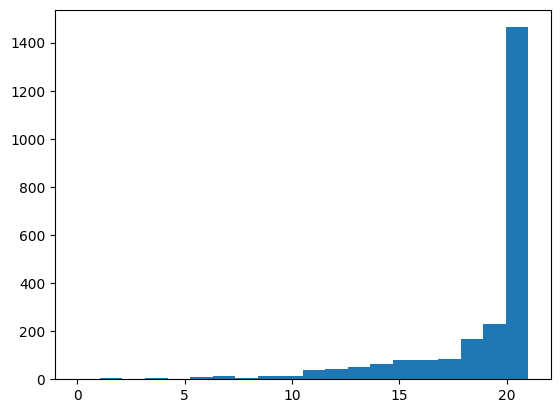

In [2]:
is_healthy = (individuals["status"] == 0)
sympt_indiv = individuals[~is_healthy].copy()
print(sympt_indiv["study_period"].max())

hh_study_period = sympt_indiv["study_period"] - sympt_indiv["onset_time"]

plt.figure()
_ = plt.hist(hh_study_period, bins=20)

max_study_period = sympt_indiv["study_period"].max()
max_hh_study_period = hh_study_period.max()

# Sampling assumption for synthetic data

In [3]:
file_name = "../output/augm.txt"
synthetic = pd.read_csv(file_name, sep=" ", index_col="index")

synthetic.drop(columns=["incub_period"], inplace=True)
synthetic["study_period"] = max_study_period

In [4]:
infinite_onset = 1000

#=====impose max in-house study period=====//
if True :
    for h in synthetic["HH_idx"].unique():
        
        # sample threshold
        mask = (synthetic["HH_idx"] == h)
        mask = mask & (synthetic["status"] == 1)

        hh_day_1 = synthetic[mask]["onset_time"].min()
        study_period = min(max_hh_study_period + hh_day_1, max_study_period)
        mask = mask & (synthetic["onset_time"] > study_period)
        synthetic.loc[mask,"status"] = 0
        
        # assign study_period
        mask = (synthetic["HH_idx"] == h)
        synthetic.loc[mask,"study_period"] = study_period
else :
    mask = (synthetic["onset_time"] > max_study_period)
    synthetic.loc[mask,"status"] = 0
    
#=====impose infinite onset=====//
mask = (synthetic["status"] == 0)
synthetic.loc[mask,"onset_time"] = 1000

#====drop household without symptmos=====// 
# NOTE min returns NaN in that case 
synthetic.dropna(inplace=True)
synthetic = synthetic.astype(np.int64)

synthetic.to_csv("../output/synthetic-database.txt", sep=" ")

/local/scratch/tmp/ipykernel_2655947/2354352318.py:18: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '247.773' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  synthetic.loc[mask,"study_period"] = study_period


In [5]:
synthetic.head()

,status,HH_idx,HH_size,study_period,vacc_status,age,isol,sex,severity,vacc_delay,recov,onset_time
index,,,,,,,,,,,,
1,1,1,3,247,2,55,1,1,0,186,0,227
2,1,1,3,247,2,60,1,2,1,199,0,226
3,1,1,3,247,2,21,1,1,1,161,0,236
4,1,2,3,235,2,36,1,2,0,187,0,219
5,1,2,3,235,2,69,1,2,1,187,1,214


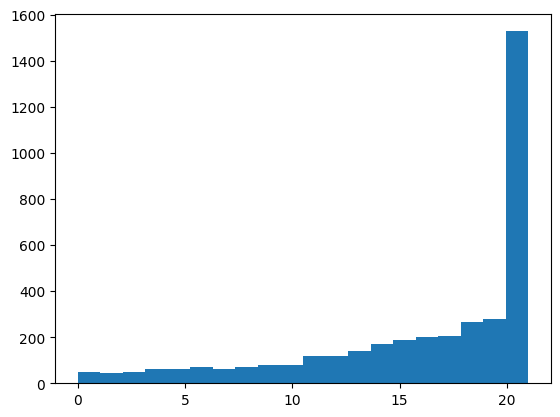

In [6]:
sympt = synthetic[synthetic["status"] == 1]
hh_study_period = sympt["study_period"] - sympt["onset_time"]

plt.figure()
_ = plt.hist(hh_study_period, bins=20)